Gold notebook: RFM stands for recency, frequency, and monetary. This way we can see when they bought, how much they bought, and the value (quantity x price)

In [2]:
from pathlib import Path
import duckdb
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "ltv.duckdb"

cols = ["Invoice", "Quantity", "InvoiceDate", "Price", "Customer_ID", "Country",
        "Customer_ID_Exists", "Cancelled_Order", "Return_Adjustment"]

with duckdb.connect(str(DB_PATH)) as con:
    silver = con.sql(f"SELECT {', '.join(cols)} FROM silver").df()

print(f"Silver rows loaded: {len(silver):,}")

Silver rows loaded: 1,067,371


In [3]:
with duckdb.connect(str(DB_PATH)) as con:
    silver = con.sql("""
        SELECT Invoice, InvoiceDate, Customer_ID, Quantity, Price,
               Customer_ID_Exists, Cancelled_Order, Return_Adjustment
        FROM silver
    """).df()

sales = silver[
    silver["Customer_ID_Exists"]
    & ~silver["Cancelled_Order"] #~ means NOT, so this is filtering out cancelled orders
    & ~silver["Return_Adjustment"] #~ means NOT, so this is filtering out returns/adjustments
    & (silver["Quantity"] > 0)
    & (silver["Price"] > 0)
].copy()
del silver

sales["line_total"] = sales["Quantity"] * sales["Price"]
print(f"Usable sales rows: {len(sales):,}")
print(f"Customers: {sales['Customer_ID'].nunique():,}")

Usable sales rows: 805,549
Customers: 5,878


In [ ]:
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
snapshot = sales["InvoiceDate"].max() + pd.Timedelta(days=1)   #as of date: day after the last invoice in the data

gold = sales.groupby("Customer_ID").agg(
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
    frequency=("Invoice", "nunique"),
    monetary=("line_total", "sum"),
).reset_index()

gold["recency_days"] = (snapshot - gold["last_purchase"]).dt.days
gold["tenure_days"] = (snapshot - gold["first_purchase"]).dt.days
gold["first_purchase_month"] = gold["first_purchase"].dt.to_period("M").astype(str)

gold["first_purchase"] = gold["first_purchase"].dt.date
gold["last_purchase"] = gold["last_purchase"].dt.date

print(f"Snapshot date: {snapshot.date()}")
print(gold.describe().round(1))
gold.head()

Snapshot date: 2011-12-10
       Customer_ID  frequency  monetary  recency_days  tenure_days
count       5878.0     5878.0    5878.0        5878.0       5878.0
mean       15315.3        6.3    3018.6         201.9        475.3
std         1715.6       13.0   14737.7         209.4        223.1
min        12346.0        1.0       3.0           1.0          1.0
25%        13833.2        1.0     348.8          26.0        314.0
50%        15314.5        3.0     898.9          96.0        531.0
75%        16797.8        7.0    2307.1         380.0        669.0
max        18287.0      398.0  608821.6         739.0        739.0


,Customer_ID,first_purchase,last_purchase,frequency,monetary,recency_days,tenure_days,first_purchase_month
0,12346,2009-12-14,2011-01-18,12,77556.46,326,726,2009-12
1,12347,2010-10-31,2011-12-07,8,5633.32,3,405,2010-10
2,12348,2010-09-27,2011-09-25,5,2019.40,76,439,2010-09
3,12349,2010-04-29,2011-11-21,4,4428.69,19,590,2010-04
4,12350,2011-02-02,2011-02-02,1,334.40,311,311,2011-02


In [14]:
# Demo: save the final gold table to a local CSV, then re-read it with a relative path
EXPORT_DIR = PROJECT_ROOT / "data" / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
gold_csv = EXPORT_DIR / "gold_customers.csv"

gold.to_csv(gold_csv, index=False)                 # save

check = pd.read_csv(gold_csv)                      # re-read
print(f"Saved to: {gold_csv.relative_to(PROJECT_ROOT)}")
print(f"Re-read {len(check):,} rows, {check.shape[1]} columns")
check.head()

Saved to: data/exports/gold_customers.csv
Re-read 5,878 rows, 8 columns


,Customer_ID,first_purchase,last_purchase,frequency,monetary,recency_days,tenure_days,first_purchase_month
0,12346,2009-12-14,2011-01-18,12,77556.46,326,726,2009-12
1,12347,2010-10-31,2011-12-07,8,5633.32,3,405,2010-10
2,12348,2010-09-27,2011-09-25,5,2019.40,76,439,2010-09
3,12349,2010-04-29,2011-11-21,4,4428.69,19,590,2010-04
4,12350,2011-02-02,2011-02-02,1,334.40,311,311,2011-02


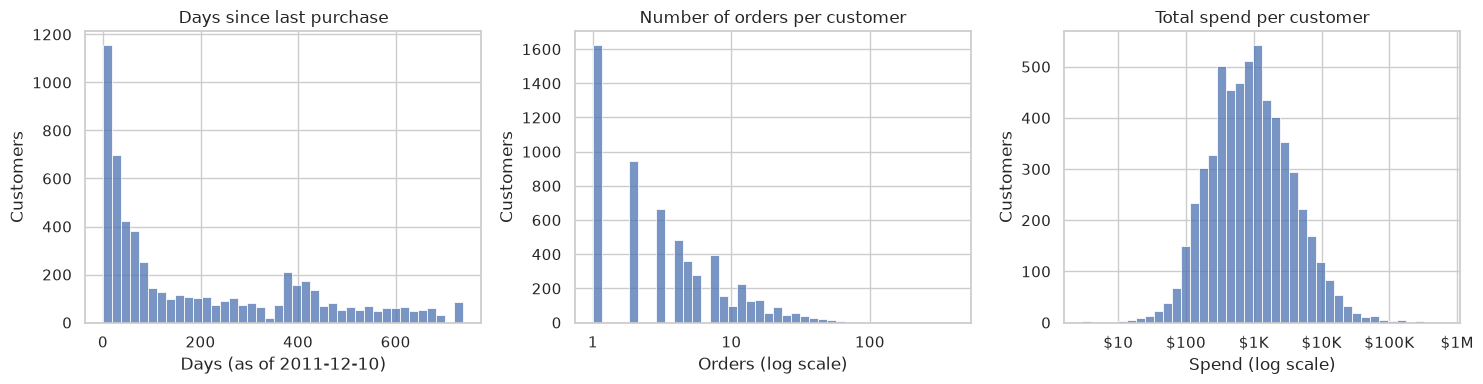

One-time customers: 27.6%


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
sns.set_theme(style="whitegrid")

def plain_number(x, _):
    return f"{x:,.0f}"

def dollars(x, _):
    if x >= 1e6: return f"${x/1e6:.0f}M"
    if x >= 1e3: return f"${x/1e3:.0f}K"
    return f"${x:.0f}"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(gold["recency_days"], bins=40, ax=axes[0])
axes[0].set_title("Days since last purchase")
axes[0].set_xlabel("Days (as of 2011-12-10)")

sns.histplot(gold["frequency"], bins=40, log_scale=True, ax=axes[1])
axes[1].set_title("Number of orders per customer")
axes[1].set_xlabel("Orders (log scale)")
axes[1].xaxis.set_major_formatter(FuncFormatter(plain_number))

sns.histplot(gold["monetary"], bins=40, log_scale=True, ax=axes[2])
axes[2].set_title("Total spend per customer")
axes[2].set_xlabel("Spend (log scale)")
axes[2].xaxis.set_major_formatter(FuncFormatter(dollars))

for ax in axes:
    ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()

print(f"One-time customers: {(gold['frequency'] == 1).mean():.1%}")